# Research notebook: frozen escm20 benchmark

**Curated source:** [`notebooks/22_original_vs_frozen_validation.ipynb`](../notebooks/22_original_vs_frozen_validation.ipynb). The experimental code and outputs below are preserved as committed; no claim of equivalence to other historical notebooks is implied.

This is the main comparison between the corrected original model and **frozen, non-fading** ESCM 2.0. Do not silently substitute the later sensory-fading benchmark: that is a distinct reference variant.

**Supporting evidence and lineage.** Origins: [17](../notebooks/17_five_pixel_competitive_replacement.ipynb) demonstrates structured five-cell competition, [18](../notebooks/18_unlabelled_spatial_competition.ipynb) removes stimulus labels from the graph, [19](../notebooks/19_spatial_generalization.ipynb) tests shapes and timing, and [20](../notebooks/20_spatial_inhibition_diagnostic.ipynb) adjusts the inhibitory annulus after measuring failures. [21](../notebooks/21_transient_spatial_disinhibition.ipynb) is an exploratory extension, **not** part of the frozen baseline. Geometry scores must be compared only under matched input and eligibility windows.

See [research/index.md](index.md) for the full 31-notebook map and definition of the benchmark variants. Run from an environment with the source notebook's original dependencies. The code cells below have **not been re-executed as part of the reorganization**.

# ESCM validation — original model versus frozen ESCM 2.0

## Purpose and fixed comparison contract

We now **stop redesigning the mechanism** and compare two already specified models on **exactly the same external event stream**:

- **Original ESCM:** LIF, \(\tau=0.2\) ms, threshold 0.1, external assignment 0.5, recurrent excitation assignment 6, counter-based inhibitory assignment \(-3\), and the original \(P\) events. We use the documented 0.5-ms clock and direct 2D neighborhood of radius 8 for the small grid. The incoming-counter pathway explicitly precedes the inhibitory pathway.
- **Frozen ESCM 2.0:** LIF with \(\tau_m=10\), \(\tau_{ext}=3\), \(\tau_E=5\), \(\tau_I=12\) ms, threshold 1, external additive jump 22, self-excitation assignment 8, and distance-weighted **surround inhibition** \(1.5<d\le5.5\), \(g_I=0.1\), \(\sigma_I=2.5\). No persistence gate, manual scheduling, or lateral excitation. We use its previously tested 0.05-ms clock.

**Important fairness distinction:** These are *model-native* parameterizations and timesteps, not a causal ablation or a comparison at equal computational accuracy. Both consume the **same events**, quantized once onto the original 0.5-ms input clock, which the 0.05-ms model can represent exactly. We also repeat ESCM 2.0 at 0.5 ms to reveal timestep effects. Do **not** interpret this comparison as evidence that a specific architectural change caused any performance difference.

**Primary synthetic outcomes:** repeated late spikes at the five correct pixels, complete suppression of obsolete pixels, off-target activity, and persistence in old-only/new-only controls. **Real recording:** spike activity and spatial concentration are descriptive only without annotated ground truth. Numerical runtime here measures Python/Brian2 execution, not optimized or deployed throughput.

No parameter is tuned after inspecting these results. The original model is included as a historical baseline even if it does not satisfy the synthetic task.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"
width = height = 9
n = width * height
xy = np.column_stack(np.unravel_index(np.arange(n), (height, width)))[:, ::-1]


def pixels(coords):
    return np.array([y * width + x for x, y in coords], dtype=int)


shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]),
                 pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]),
                   pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]),
                 pixels([(x + 3, x) for x in range(1, 6)])),
    "L shape": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}
for old, new in shapes.values():
    assert len(old) == len(new) == 5 and len(np.unique(np.r_[old, new])) == 10
print("Fixed models, 9x9 grid, five geometries; no fitted parameters")

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fixed models, 9x9 grid, five geometries; no fitted parameters


## 1. Identical camera events, two different recurrent systems

Each input is a pair of arrays: pixel IDs and times in milliseconds. Duplicate camera events in the **same pixel and 0.5-ms tick** are collapsed, consistent with the legacy baseline's input preprocessing. This happens **once, before either network is built**; the same pair of arrays is then supplied to both models.

The reference model is copied from the original baseline formulation: its inhibition is an assignment proportional to an incoming-spike counter and uses the original persistence event timing. This is deliberately **not simplified** into the new inhibition mechanism.

The frozen model is copied from the last fixed-surround formulation, not the experimental disinhibition variant.

In [2]:
def canonical_events(ids, times_ms, grid_ms=0.5):
    ids = np.asarray(ids, dtype=np.int64)
    times_ms = np.asarray(times_ms, dtype=float)
    assert ids.shape == times_ms.shape
    assert np.all((ids >= 0) & (ids < n)) and np.all(np.isfinite(times_ms))
    assert np.all(times_ms >= 0)
    ticks = np.floor(times_ms / grid_ms + 1e-9).astype(np.int64)
    pairs = np.unique(np.column_stack((ticks, ids)), axis=0)
    return pairs[:, 1].astype(int), pairs[:, 0].astype(float) * grid_ms


def run_model(model, ids, times_ms, dt_ms, duration_ms=130.0):
    assert model in ("original", "frozen")
    assert duration_ms > (np.max(times_ms) if len(times_ms) else 0)
    b2.start_scope()
    b2.defaultclock.dt = dt_ms * b2.ms
    camera = b2.SpikeGeneratorGroup(n, ids, times_ms * b2.ms)

    if model == "original":
        params = dict(tau=0.2*b2.ms, vt=0.1, vr=0., beta=0.5,
                      Wi=6.0, Wk=-3.0)
        equations = """
            dv/dt = (-v + ExtIn + P*(Inh + Exc))/tau : 1
            dExtIn/dt = -ExtIn/tau : 1
            dExc/dt = -Exc/tau : 1
            dInh/dt = -Inh/tau : 1
            incoming_spikes : integer
            P : integer
        """
        neurons = b2.NeuronGroup(
            n, equations, threshold="v > vt",
            reset="v = vr; incoming_spikes = 0", refractory=0*b2.ms,
            events={"P_ON": "v > vt",
                    "P_OFF": "(timestep(t - lastspike, dt) > timestep(dt, dt) and v <= vt)"},
            method="exact", namespace=params)
        neurons.v = neurons.ExtIn = neurons.Exc = neurons.Inh = 0
        neurons.P = neurons.incoming_spikes = 0
        neurons.set_event_schedule("P_ON", when="after_thresholds")
        neurons.run_on_event("P_ON", "P = 1", when="after_thresholds")
        neurons.set_event_schedule("P_OFF", when="groups")
        neurons.run_on_event("P_OFF", "P = 0", when="groups")
        feed = b2.Synapses(camera, neurons, on_pre="ExtIn_post = beta", namespace=params)
        feed.connect(j="i")
        recurrent = b2.Synapses(neurons, neurons,
            on_pre={"pre": "incoming_spikes_post += 1; Exc_pre = Wi",
                    "pre_2": "Inh_post = P_post * Wk * incoming_spikes_post"},
            namespace=params)
        recurrent.pre.order = 0
        recurrent.pre_2.order = 1
        # Identical Chebyshev neighborhood to the original k=8 rule (no autapses).
        pre, post = np.where(np.max(np.abs(xy[:, None, :] - xy[None, :, :]), axis=2) <= 8)
        keep = pre != post
        recurrent.connect(i=pre[keep], j=post[keep])
        objects = [camera, neurons, feed, recurrent]
    else:
        params = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=5*b2.ms, tau_inh=12*b2.ms,
                      v_threshold=1.0, camera_gain=22.0, self_gain=8.0)
        equations = """
            dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
            dIext/dt = -Iext/tau_ext : 1
            dIexc/dt = -Iexc/tau_exc : 1
            dIinh/dt = -Iinh/tau_inh : 1
        """
        neurons = b2.NeuronGroup(n, equations, threshold="v > v_threshold",
                                 reset="v = 0", method="exact", namespace=params)
        neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0
        feed = b2.Synapses(camera, neurons, on_pre="Iext_post += camera_gain",
                           namespace=params)
        feed.connect(j="i")
        autapse = b2.Synapses(neurons, neurons, on_pre="Iexc_post = self_gain",
                              namespace=params)
        autapse.connect(i=np.arange(n), j=np.arange(n))
        dist = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)
        post, pre = np.where((dist > 1.5) & (dist <= 5.5))
        lateral = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        lateral.connect(i=pre, j=post)
        lateral.w = 0.1*np.exp(-dist[post, pre]**2/(2*2.5**2))
        objects = [camera, neurons, feed, autapse, lateral]

    monitor = b2.SpikeMonitor(neurons)
    objects.append(monitor)
    before = perf_counter()
    b2.Network(*objects).run(duration_ms*b2.ms)
    runtime_s = perf_counter()-before
    return {"t": np.asarray(monitor.t/b2.ms),
            "i": np.asarray(monitor.i, dtype=int),
            "runtime_s": runtime_s}

# Minimal checks: input is identical and no camera event is silently shifted.
a, t = canonical_events([0, 0, 1, 1], [2.0, 2.1, 2.0, 2.5])
assert a.tolist() == [0, 1, 1] and t.tolist() == [2.0, 2.0, 2.5]
print("Event canonicalization: PASS")

Event canonicalization: PASS


## 2. Frozen synthetic test set and explicit success criteria

Five geometries are tested under three protocols: **old-only**, **new-only**, and **old followed by new**. Each pixel receives three camera events at 2, 4, 6 ms or 40, 42, 44 ms. After 44 ms there are no new camera events.

Success is evaluated in **two disjoint late windows**: 90–105 ms and 105–120 ms. A pixel is persistent only if it fires **at least twice in each** window. A replaced old pixel must be silent in **both** windows. No unrelated pixel may spike in either. This is a deliberately stringent definition, not a threshold optimized for either model.

For the original model, synthetic trials are outside its original camera-data operating regime. Failure here is a result for these inputs and parameters, **not** a claim that the original model never works.

In [3]:
windows = ((90., 105.), (105., 120.))

def input_for(edge, pulses):
    return [(int(p), float(t)) for t in pulses for p in edge]


def per_pixel(run, indices):
    return np.array([[np.count_nonzero((run["i"] == p) &
             (run["t"] >= left) & (run["t"] < right)) for p in indices]
             for left, right in windows])


def evaluate_triplet(old_ctrl, new_ctrl, replacement, old, new):
    old_base = per_pixel(old_ctrl, old)
    new_base = per_pixel(new_ctrl, new)
    old_after = per_pixel(replacement, old)
    new_after = per_pixel(replacement, new)
    others = np.setdiff1d(np.arange(n), np.r_[old, new])
    extra = per_pixel(replacement, others)
    result = dict(
        old_control=int(np.sum((old_base >= 2).all(axis=0))),
        new_control=int(np.sum((new_base >= 2).all(axis=0))),
        old_silent=int(np.sum((old_after == 0).all(axis=0))),
        new_persistent=int(np.sum((new_after >= 2).all(axis=0))),
        off_target=int(np.sum((extra > 0).any(axis=0))),
    )
    result["success"] = (result["old_control"] == 5 and
       result["new_control"] == 5 and result["old_silent"] == 5 and
       result["new_persistent"] == 5 and result["off_target"] == 0)
    return result

records = []
examples = {}
for geometry, (old, new) in tqdm(shapes.items(), desc="Matched geometry trials"):
    old_events = input_for(old, (2., 4., 6.))
    new_events = input_for(new, (40., 42., 44.))
    for model, dt in (("original", 0.5), ("frozen", 0.05), ("frozen", 0.5)):
        runs = []
        for events in (old_events, new_events, old_events + new_events):
            ids, ts = canonical_events(*zip(*events))
            runs.append(run_model(model, ids, ts, dt))
        scores = evaluate_triplet(*runs, old, new)
        records.append(dict(geometry=geometry, model=model, dt_ms=dt,
                            **scores, total_spikes=len(runs[2]["i"]),
                            runtime_s=sum(r["runtime_s"] for r in runs)))
        if geometry in ("vertical", "diagonal"):
            examples[(geometry, model, dt)] = runs[2]

comparison = pd.DataFrame(records)
display(comparison)
print("Successful geometries by model and clock:")
display(comparison.groupby(["model", "dt_ms"], as_index=False)["success"].sum())

Matched geometry trials:   0%|          | 0/5 [00:00<?, ?it/s]WARNING    't' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([2. , 2. , 2.5]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'dt' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 0.5. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    't' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([2. , 2. , 2.5]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'dt' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 0.5. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
Matched geometry trials: 100%|██████████| 5/5 

,geometry,model,dt_ms,old_control,new_control,old_silent,new_persistent,off_target,success,total_spikes,runtime_s
0,vertical,original,0.50,0,0,5,0,0,False,40,0.821282
1,vertical,frozen,0.05,5,5,5,5,0,True,493,2.613983
2,vertical,frozen,0.50,5,5,3,5,0,False,470,0.422674
3,horizontal,original,0.50,0,0,5,0,0,False,40,0.519509
4,horizontal,frozen,0.05,5,5,5,5,0,True,493,0.814947
5,horizontal,frozen,0.50,5,5,3,5,0,False,470,0.426789
6,diagonal,original,0.50,0,0,5,0,0,False,40,0.428620
7,diagonal,frozen,0.05,5,5,3,5,0,False,594,0.730327
8,diagonal,frozen,0.50,5,5,3,5,0,False,506,0.484385
9,L shape,original,0.50,0,0,5,0,0,False,40,0.483204


Successful geometries by model and clock:


,model,dt_ms,success
0,frozen,0.05,3
1,frozen,0.50,0
2,original,0.50,0


## 3. Inspect spatial failures, not only aggregate scores

We visualize the distribution of **late spikes** in the replacement protocol for a geometry known to work with the frozen model (vertical) and a previously difficult geometry (diagonal). These maps expose partial suppression, mutual extinction, and stray persistent pixels. Raw spike count is not a normalized measure of quality because the two models have different membrane and synaptic timescales.

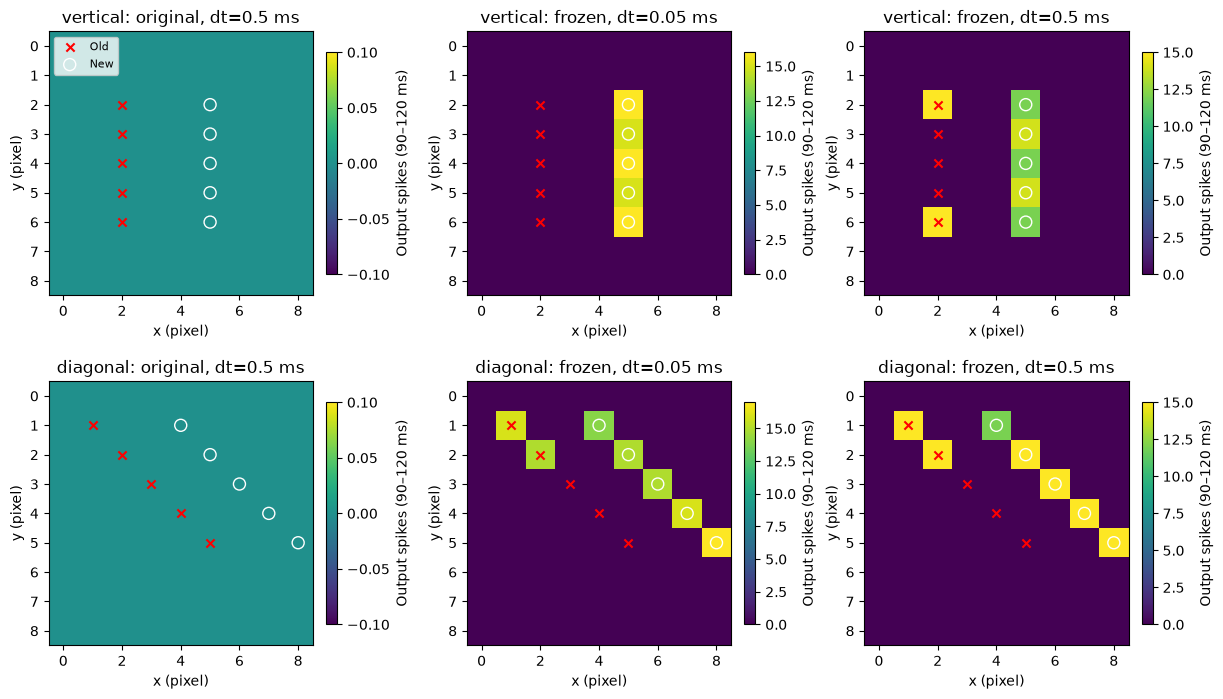

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for row, geometry in enumerate(("vertical", "diagonal")):
    old, new = shapes[geometry]
    for col, (model, dt) in enumerate((("original", 0.5),
                                      ("frozen", 0.05), ("frozen", 0.5))):
        run = examples[(geometry, model, dt)]
        late = (run["t"] >= 90) & (run["t"] < 120)
        counts = np.bincount(run["i"][late], minlength=n).reshape(height, width)
        ax = axes[row, col]
        im = ax.imshow(counts, cmap="viridis", vmin=0)
        ax.scatter(xy[old, 0], xy[old, 1], marker="x", c="red", s=35, label="Old")
        ax.scatter(xy[new, 0], xy[new, 1], marker="o", facecolors="none",
                   edgecolors="white", s=75, label="New")
        ax.set(title=f"{geometry}: {model}, dt={dt:g} ms",
               xlabel="x (pixel)", ylabel="y (pixel)")
        fig.colorbar(im, ax=ax, label="Output spikes (90–120 ms)", shrink=0.75)
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.show()

## 4. Real event-camera data (optional, same processing for both models)

If the repository contains the MVSEC recording used in the original ESCM baseline, we load it through the **existing** `escm.event_input.load_events` utility. The notebook deliberately **does not download, substitute, or fabricate** real data.

The original recording has 346 × 260 pixels; simulating its full recurrent original connectivity would require tens of millions of connections. For a tractable *first real-data comparison*, we use a **9 × 9 region of interest** selected **using input event counts only**, before looking at output. This tests behavior on genuine events but **is not a full-frame accuracy benchmark**: the ROI discards the rest of the scene and changes the original network's neighborhood boundaries.

We select a region centered on the most active pixel in the first 100 ms, then keep the first 100 ms of events and run until 200 ms. We restrict the input to at most 10,000 distinct pixel/tick events to control runtime; if the limit is reached, we report truncation and do not treat the run as unbiased evidence. **No annotated object or edge ground truth is assumed.**

In [5]:
try:
    from escm.event_input import load_events
except ImportError:
    load_events = None

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists()), None)
recording_path = (root / "InputData/MVSEC_short_outdoor/leftdvs"
                  if root is not None else None)

if load_events is None or recording_path is None or not recording_path.exists():
    print("SKIP: no locally accessible MVSEC recording or escm.event_input loader.")
    real_results = pd.DataFrame()
else:
    recording = load_events(recording_path, channel="left", width=346, height=260,
                            timestamp_clock_ns=1000)
    events = recording["events"]
    ts = np.asarray(events["ts"], dtype=float)
    xs = np.asarray(events["x"], dtype=int)
    ys = np.asarray(events["y"], dtype=int)
    mask = (ts >= ts[0]) & (ts < ts[0] + 0.100)
    active = np.bincount(ys[mask]*346 + xs[mask], minlength=346*260)
    peak = int(np.argmax(active))
    x0 = np.clip(peak % 346 - 4, 0, 346 - width)
    y0 = np.clip(peak // 346 - 4, 0, 260 - height)
    roi = mask & (xs >= x0) & (xs < x0+width) & (ys >= y0) & (ys < y0+height)
    raw_ids = (ys[roi]-y0)*width + (xs[roi]-x0)
    raw_times = (ts[roi]-ts[0])*1000.0
    ids, times = canonical_events(raw_ids, raw_times)
    print(f"ROI x=[{x0},{x0+8}], y=[{y0},{y0+8}]; input events={len(ids)}")
    if not len(ids):
        print("SKIP: selected ROI has no events")
        real_results = pd.DataFrame()
    elif len(ids) > 10000:
        print("SKIP: ROI exceeds the predeclared 10,000-event cap; no silent truncation")
        real_results = pd.DataFrame()
    else:
        rows = []
        for model, dt in tqdm((("original", 0.5), ("frozen", 0.05),
                              ("frozen", 0.5)), desc="Real ROI comparison"):
            result = run_model(model, ids, times, dt, duration_ms=200.0)
            late = result["t"] >= 120.0
            counts = np.bincount(result["i"][late], minlength=n)
            rows.append(dict(model=model, dt_ms=dt, input_events=len(ids),
                             output_spikes=len(result["i"]),
                             no_input_spikes=int(late.sum()),
                             no_input_active_pixels=int(np.count_nonzero(counts)),
                             runtime_s=result["runtime_s"]))
        real_results = pd.DataFrame(rows)
        display(real_results)

importIitYarp trying path: /home/bmaacaron-iit.local/Documents/GitRepos/Event-SCM-Refactor/InputData/MVSEC_short_outdoor/leftdvs


100%|██████████| 38292/38292 [00:05<00:00, 7204.35it/s] 


Examining info.log: /home/bmaacaron-iit.local/Documents/GitRepos/Event-SCM-Refactor/InputData/MVSEC_short_outdoor/leftdvs/info.log
ROI x=[281,289], y=[8,16]; input events=27


Real ROI comparison: 100%|██████████| 3/3 [00:00<00:00,  4.38it/s]


,model,dt_ms,input_events,output_spikes,no_input_spikes,no_input_active_pixels,runtime_s
0,original,0.50,27,208,80,1,0.173049
1,frozen,0.05,27,412,97,2,0.297937
2,frozen,0.50,27,322,80,2,0.127834


## 5. Interpretation and stopping rule

The **synthetic test** has five predetermined geometries, identical input events, separate persistence controls, and fixed late-window criteria. Report each model's observed successes, failures, off-target spikes, and runtime, including the original model's own clock. Model-level superiority cannot be generalized from five designed geometries alone.

The **real ROI test** establishes only that both models process an identical subset of a real recording. Without ground-truth labels or independent evaluation of retained structure, its spike counts are descriptive, not proof of better perceptual performance. This ROI benchmark does not validate full-resolution throughput or original camera geometry.

The **comparison is complete as a first-stage validation** when all runs either finish or fail visibly. Do not tune the frozen model to improve this table. Follow-up, if justified, is a predeclared unseen synthetic test set and a full-frame or sampled-spatially faithful real-data benchmark, subject to available memory and labeled data.

**Reproducibility record:** Brian2 uses its NumPy backend, no random seeds or stochastic inputs are used, input canonicalization is deterministic, and both models receive identical event arrays. The actual Brian2 version and environment should be recorded with the executed notebook.

In [6]:
print("Brian2 version:", b2.__version__)
print("NumPy version:", np.__version__)
print("Frozen synthetic successes:")
display(comparison.groupby(["model", "dt_ms"], as_index=False).agg(
    successes=("success", "sum"),
    mean_off_target=("off_target", "mean"),
    total_runtime_s=("runtime_s", "sum")))
if real_results.empty:
    print("Real recording comparison: not executed (see skip reason above).")
else:
    display(real_results)

Brian2 version: 2.10.1
NumPy version: 2.5.4
Frozen synthetic successes:


,model,dt_ms,successes,mean_off_target,total_runtime_s
0,frozen,0.05,3,0.0,5.598361
1,frozen,0.50,0,0.0,2.080825
2,original,0.50,0,0.0,2.660404


,model,dt_ms,input_events,output_spikes,no_input_spikes,no_input_active_pixels,runtime_s
0,original,0.50,27,208,80,1,0.173049
1,frozen,0.05,27,412,97,2,0.297937
2,frozen,0.50,27,322,80,2,0.127834
